In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


In [4]:
df = pd.read_csv('../data/features.csv')
x = df.drop(columns=['label']).values
y = df['label'].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

n_total = len(y_train)
n_spam  = y_train.sum()
n_ham   = (y_train == 0).sum()
sample_weights = np.where(y_train == 1,
                          n_total/(2*n_spam),
                          n_total/(2*n_ham))

def sigmoid(z):
    return 1/ (1 + np.exp(-np.clip(z, -500, 500)))

def train_lr(x, y, weights, lr, epochs=1000):
    w = np.zeros(x.shape[1])
    b = 0.0
    losses = []
    for _ in range(epochs):
        y_pred = sigmoid(x@w + b)
        y_pred_clip = np.clip(y_pred, 1e-15, 1 - 1e-15)
        loss = -np.mean(weights * (y * np.log(y_pred_clip)+
                            (1 - y) * np.log(1 - y_pred_clip)))
        losses.append(loss)
        error = (y_pred - y) * weights
        w -= lr * (1/len(y)) * x.T@ error
        b -= lr * (1/len(y)) * np.sum(error)

    return w, b, losses

learning_rates = [0.001, 0.01, 0.1]
colors = ['#F44747', '#4EC9B0', '#CE9178']
result = {}

for lr, color in zip(learning_rates, colors):
    w, b, losses = train_lr(x_train, y_train, sample_weights, lr)
    y_pred = (sigmoid(x_test @ w + b) >= 0.5).astype(int)
    acc = accuracy_score(y_test, y_pred)
    result[lr] = {"losses": losses, 'accuracy': acc}
    print(f'lr={lr}, Final Loss: {losses[-1]:.4f}, Test Accuracy: {acc*100:.2f}%')

lr=0.001, Final Loss: 0.4183, Test Accuracy: 85.29%
lr=0.01, Final Loss: 0.2227, Test Accuracy: 94.08%
lr=0.1, Final Loss: 0.1568, Test Accuracy: 96.14%


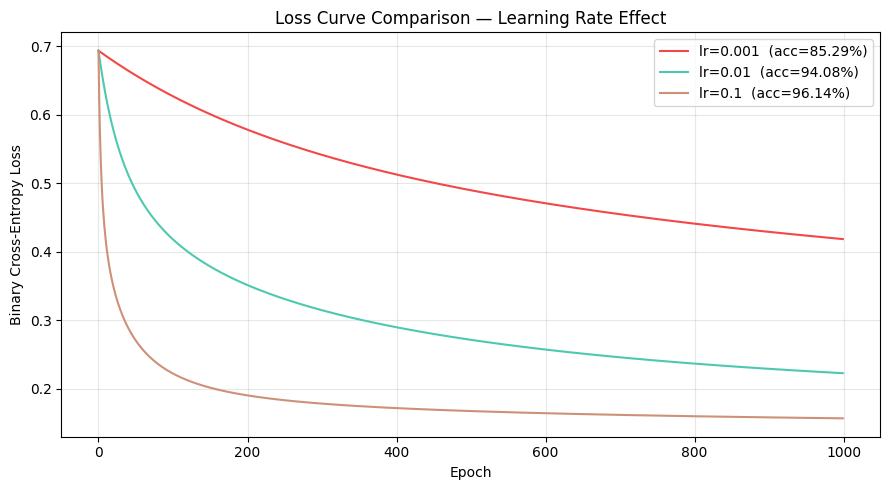

In [6]:
plt.figure(figsize=(9, 5))
for lr, color in zip(learning_rates, colors):
    plt.plot(result[lr]["losses"],
             label=f"lr={lr}  (acc={result[lr]['accuracy']*100:.2f}%)",
             color=color, linewidth=1.5)

plt.title("Loss Curve Comparison — Learning Rate Effect")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../results/loss_curve_lr_comparison.png", dpi=150)
plt.show()

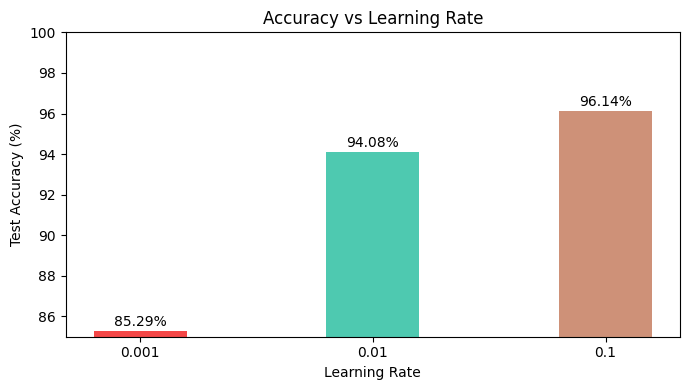

In [8]:
lrs   = [str(lr) for lr in learning_rates]
accs  = [result[lr]["accuracy"] * 100 for lr in learning_rates]
colors_bar = ["#F44747", "#4EC9B0", "#CE9178"]

plt.figure(figsize=(7, 4))
bars = plt.bar(lrs, accs, color=colors_bar, width=0.4)
plt.title("Accuracy vs Learning Rate")
plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy (%)")
plt.ylim(85, 100)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
             f'{acc:.2f}%', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig("../results/accuracy_vs_lr.png", dpi=150)
plt.show()

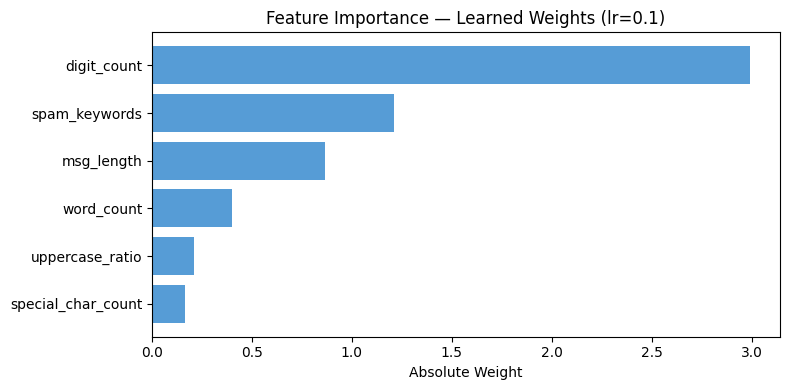

Feature weights:
  msg_length             +0.8637
  word_count             -0.4002
  digit_count            +2.9925
  special_char_count     +0.1636
  uppercase_ratio        +0.2075
  spam_keywords          +1.2091


In [10]:
w_final, b_final, _ = train_lr(x_train, y_train, sample_weights, lr=0.1)

feature_names = ["msg_length", "word_count", "digit_count",
                 "special_char_count", "uppercase_ratio", "spam_keywords"]
importance = np.abs(w_final)
sorted_idx = np.argsort(importance)

plt.figure(figsize=(8, 4))
plt.barh([feature_names[i] for i in sorted_idx],
         importance[sorted_idx],
         color="#569CD6")
plt.title("Feature Importance — Learned Weights (lr=0.1)")
plt.xlabel("Absolute Weight")
plt.tight_layout()
plt.savefig("../results/feature_importance.png", dpi=150)
plt.show()

print("Feature weights:")
for name, w in zip(feature_names, w_final):
    print(f"  {name:<22} {w:+.4f}")

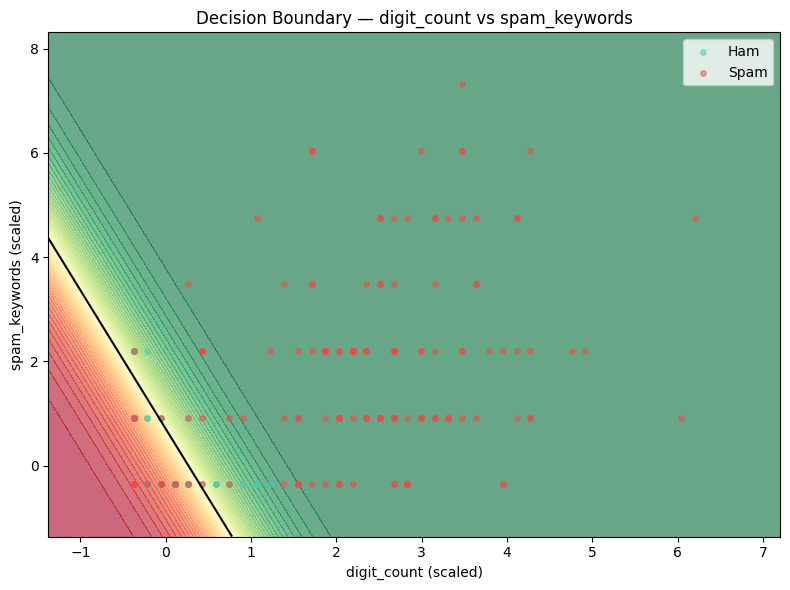

In [12]:
feat_idx = [2, 5]
X_2d = x[:, feat_idx]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)
scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train_2d)
X_test_2d  = scaler_2d.transform(X_test_2d)

n_total = len(y_train_2d)
n_spam  = y_train_2d.sum()
n_ham   = (y_train_2d == 0).sum()
sw_2d = np.where(y_train_2d == 1,
                 n_total/(2*n_spam),
                 n_total/(2*n_ham))

w_2d, b_2d, _ = train_lr(X_train_2d, y_train_2d, sw_2d, lr=0.1)

x_min, x_max = X_test_2d[:, 0].min() - 1, X_test_2d[:, 0].max() + 1
y_min, y_max = X_test_2d[:, 1].min() - 1, X_test_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = sigmoid(grid @ w_2d + b_2d).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, levels=50, cmap="RdYlGn", alpha=0.6)
plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1.5)
plt.scatter(X_test_2d[y_test_2d==0, 0], X_test_2d[y_test_2d==0, 1],
            c="#4EC9B0", label="Ham", alpha=0.5, s=15)
plt.scatter(X_test_2d[y_test_2d==1, 0], X_test_2d[y_test_2d==1, 1],
            c="#F44747", label="Spam", alpha=0.5, s=15)
plt.title("Decision Boundary — digit_count vs spam_keywords")
plt.xlabel("digit_count (scaled)")
plt.ylabel("spam_keywords (scaled)")
plt.legend()
plt.tight_layout()
plt.savefig("../results/decision_boundary.png", dpi=150)
plt.show()

In [13]:
import pickle 
model_data = {
    'weights': w_final,
    'bias': b_final,
    'scaler': scaler,
    'feature_names': feature_names
}

with open('../models/logistic_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print('Model saved')
print(f'Weights: {w_final}')
print(f'Bias: {b_final:.4f}')

Model saved
Weights: [ 0.86367148 -0.40017994  2.99249779  0.16357011  0.20747932  1.20911393]
Bias: -1.1335
